In [19]:
import os
import jax
from astropy.table import Table
import numpy as np
import jax.numpy as jnp
from astropy.coordinates import SkyCoord
import astropy.units as u
import matplotlib.pyplot as plt
from dustmaps.config import config
import healpy as hp
import astropy as ap
from astropy.coordinates import SkyCoord
import jax.random as jr
from astropy.io import fits
from hmc_dust.better_hmc import HMCSampler 
import jax.scipy.special as jss
import arviz as az
import blackjax
from jax.scipy.stats import t
from jax.scipy.special import logsumexp
from jax.scipy.special import gammaln
from jax.scipy.stats import norm
import graphgp as gp

jax.config.update("jax_enable_x64", True)

from scipy.special import gamma, jv, kv, j0

from pathlib import Path

RESULTS = Path.home() / "hmc-dust" / "sherlock_results" / "hankel_1d_46926049"

overall_data_arr = jnp.asarray(np.load(RESULTS / "overall_data_1D_hankel.npy"))


def compute_hankel_matrix(k, r, *, d):
    """
    Compute matrix to convert P(k) to C(r) via Hankel transform in d dimensions.
    Assumes P(k) is piecewise constant between k bins, output will have shape (len(r), len(k)-1).
    Requires scipy for Bessel functions, so this cannot be differentiated through.
    """
    k = np.asarray(k, dtype=float)
    r = np.asarray(r, dtype=float)[:, None]
 
    # Both branches of np.where get evaluated, so the r = 0 rows produce
    # harmless inf/nan values in `limits` that are discarded. Silence the warnings.
    with np.errstate(divide="ignore", invalid="ignore"):
        limits = (k / (2 * np.pi * r)) ** (d / 2) * jv(d / 2, k * r)
 
    zero = (k / 2) ** d / (np.pi ** (d / 2) * gamma(d / 2 + 1))
    weights = np.where(
        r > 0,
        limits[:, 1:] - limits[:, :-1],
        zero[None, 1:] - zero[None, :-1],
    )
    return weights


 
def covariance_from_spectrum(cov_bins, logk, *, d):
    """
    Create a function which converts a discretized power spectrum to a discretized covariance.
    Certain values must be precomputed outside of JAX, hence the factory function.
    Specifically, this computes the integrals analytically using Bessel functions assuming piecewise constant P(k).
 
    Args:
        cov_bins: Radial bins at which to evaluate the covariance. First entry should probably be zero.
        logk: Logarithmic k values defining the upper edges of the power spectrum bins. The first bin is assumed to start at k=0.
        d: Dimensionality of the space.
 
    Returns:
        cov_func: Callable taking logarithmic power spectrum in the defined k bins, plus overall variance kwarg, returning covariance values at cov_bins.
    """
    # Precompute Hankel matrix with NumPy/SciPy, then hand it to JAX
    k = np.concatenate([[0.0], np.exp(np.asarray(logk, dtype=float))])
    hankel_matrix = jnp.asarray(compute_hankel_matrix(k, cov_bins, d=d))
 
    def cov_func(logp, *, variance):
        cov_vals = hankel_matrix @ jnp.exp(logp)   # absolute, not renormalized
        return cov_vals.at[0].set(variance)        # missing tail power -> nugget at r = 0
        return cov_vals
 
    return cov_func

logk = jnp.linspace(-10, 10, 4000)
cov_bins = jnp.linspace(0, 2000, 2000)
d = 1

usable_cov_func = covariance_from_spectrum(cov_bins, logk, d=d)

In [20]:
NUM_DIMENSIONS = 1
toy_logvar = jnp.log(1)
toy_lognu = jnp.log(0.5)
inv_gamma_variance_prior_alpha = jnp.exp(0.1251910775899887)
inv_gamma_variance_prior_beta  = jnp.exp(1.294155478477478)

from hmc_dust import DATA, GAIA
fits_table = Table.read(GAIA / "gc_sightline.fits")

gc_builtin = SkyCoord(0*u.deg, 0*u.deg, frame='galactic').icrs

star_coords = SkyCoord(np.asarray(fits_table["ra"])*u.deg, np.asarray(fits_table["dec"])*u.deg)
fits_table["sep_gc_deg"] = star_coords.separation(gc_builtin).deg


plx_np = fits_table["parallax"]              # parallax measurements (mas)
plx = jnp.asarray(np.asarray(plx_np).astype(np.float32))
plx_err_np = fits_table["parallax_err"]         # their uncertainties (mas)
plx_err = jnp.asarray(np.asarray(plx_err_np).astype(np.float32))
ext_np  = fits_table["ext"]                  # extinction
ext = jnp.asarray(np.asarray(ext_np).astype(np.float32))
ext_err_np = fits_table["ext_err"]
ext_err = jnp.asarray(np.asarray(ext_err_np).astype(np.float32))
sep_np = fits_table["sep_gc_deg"]
separation = jnp.asarray(np.asarray(sep_np).astype(np.float32))
print(fits_table.info())

with fits.open(DATA / "mean_and_std_healpix.fits") as hdul:
    hdul.info()
    print(hdul['MEAN'].header['ORDERING'])
    print(hdul['STD.'].header['ORDERING'])
    galactic_center_healpix = hp.pixelfunc.ang2pix(256, theta = 0.0, phi = 0.0, nest = True, lonlat = True)
    mean_along_center = jnp.asarray(hdul["MEAN"].data[:, galactic_center_healpix].astype(np.float32))
    std_along_center  = jnp.asarray(hdul["STD."].data[:, galactic_center_healpix].astype(np.float32))
    radial_centers    = jnp.asarray(hdul["RADIAL PIXEL CENTERS"].data.field(0),    dtype=jnp.float32)
    radial_boundaries = jnp.asarray(hdul["RADIAL PIXEL BOUNDARIES"].data.field(0), dtype=jnp.float32)
    distance_gaps = np.diff(radial_boundaries)

# 1000/x is its own inverse so this fcn is also plx_to_dist
def dist_to_plx(dist):
    return 1000/dist

def get_x_err_basic(plx_err, plx):
    return 1000*(plx**(-2))*plx_err

def logposterior_on_r(r, w, w_err):
    p_w_given_r = -0.5*(w - 1000/r)**2/(w_err**2) 
    p_r = distance_logprior(r)
    return p_r + p_w_given_r

def get_x_err_advanced(plx_err, plx):
    x = jnp.linspace(0.1, 100000, 20000)
    log_posterior = logposterior_on_r(x, plx, plx_err)
    y = jnp.exp(log_posterior - jnp.max(log_posterior))
    Z    = jnp.trapezoid(y, x)                    
    mean = jnp.trapezoid(x * y, x) / Z
    var  = jnp.trapezoid((x - mean) ** 2 * y, x) / Z
    return jnp.sqrt(var)

def distance_logprior(r):
    return jnp.where(r > 0, -r/10000 + 2*jnp.log(r), -jnp.inf)




assert mean_along_center.shape == distance_gaps.shape
num_stars = plx.size
distances_psc = dist_to_plx(plx)

num_dimensions = 600
left_distance_padding = 40
right_distance_padding = 600


student_t_sigma = jnp.sqrt(inv_gamma_variance_prior_beta/inv_gamma_variance_prior_alpha)
student_t_nu = 2*inv_gamma_variance_prior_alpha


min_distance = radial_boundaries[0] - left_distance_padding
max_distance = radial_boundaries[radial_boundaries.size - 1] + right_distance_padding
dx = (max_distance - min_distance)/(num_dimensions - 1)
fixed_logscale = jnp.log(2*(max_distance - min_distance))


<Table length=54602>
     name       dtype 
-------------- -------
gdr3_source_id   int64
            ra float32
           dec float32
      parallax float32
  parallax_err float32
           ext float32
       ext_err float32
        teff_K float32
           feh float32
          logg float32
  plx_over_err float32
    sep_gc_deg float64
None
Filename: /home/dtfrake/hmc-dust/Data_And_Samplers/mean_and_std_healpix.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       9   ()      
  1  MEAN          1 ImageHDU        19   (786432, 516)   float32   
  2  STD.          1 ImageHDU        19   (786432, 516)   float32   
  3  RADIAL PIXEL CENTERS    1 BinTableHDU     20   516R x 1C   [E]   
  4  RADIAL PIXEL BOUNDARIES    1 BinTableHDU     20   517R x 1C   [E]   
  5  MEAN OF INTEGRATED INNER 68.8 PC    1 ImageHDU        16   (786432,)   float32   
  6  STD. OF INTEGRATED INNER 68.8 PC    1 ImageHDU        16   (786432,)   float32   
NEST


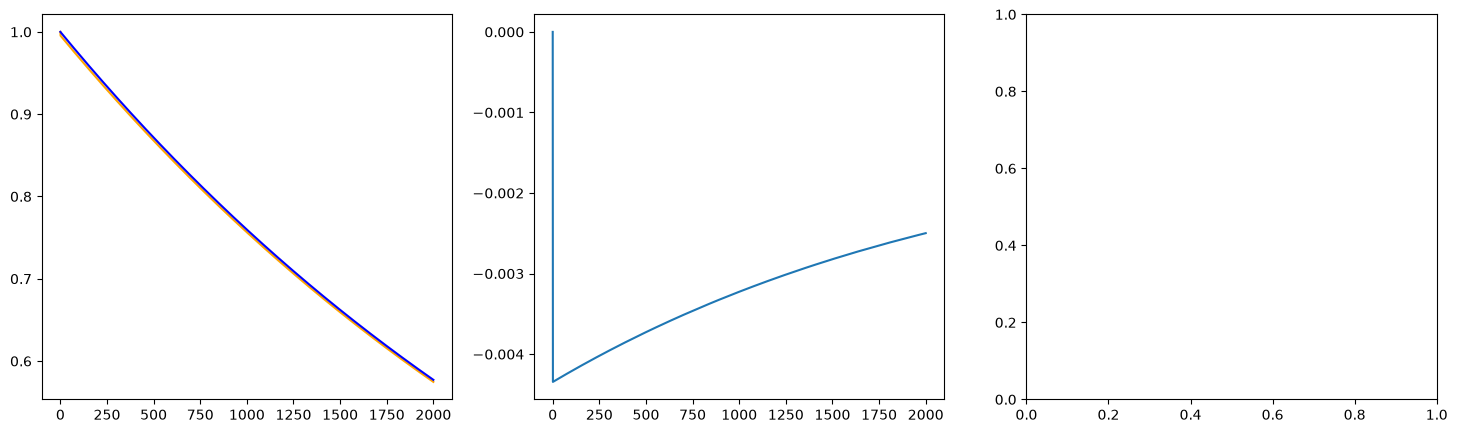

In [21]:
def matern_log_spectral_density(omega, params, d=NUM_DIMENSIONS):
    logvar, lognu = params
    logscale = fixed_logscale
    nu = jnp.exp(lognu)
    log_norm = (logvar
                + d * jnp.log(2 * jnp.sqrt(jnp.pi))
                + jss.gammaln(nu + d / 2) - jss.gammaln(nu)
                + d * (logscale - 0.5 * jnp.log(2 * nu)))
    x = jnp.square(omega) * jnp.exp(2 * logscale - jnp.log(2.0) - lognu)
    return log_norm - (nu + d / 2) * jnp.log1p(x)


logp = matern_log_spectral_density(jnp.exp(logk), (toy_logvar, toy_lognu))
cov_at_cov_bins = usable_cov_func(logp, variance=jnp.exp(toy_logvar))

def matern_32(r, variance=jnp.exp(toy_logvar), scale=jnp.exp(fixed_logscale), jitter=1e-6):
    result = variance * (1 + jnp.sqrt(3)*r/scale)*jnp.exp(-1*jnp.sqrt(3)*r/scale);
    return jnp.where(r > 0, result, result * (1.0 + jitter))

def interpolated_matern_covariance(r, params, d = NUM_DIMENSIONS):
    return jnp.interp(r, cov_bins, cov_at_cov_bins)


# Grid points (equivalent to your dx spacing)
x = jnp.linspace(min_distance, max_distance, num_dimensions)
dx = x[1] - x[0]
DIST_MATRIX = jnp.abs(x[:, None] - x[None, :])
integrating_dims_padding_left = 20
integrating_dims_padding_right = 300
total_integrating_dims = integrating_dims_padding_left + integrating_dims_padding_right + num_dimensions
integrating_dust_x_linspace = jnp.arange(num_dimensions + integrating_dims_padding_left + integrating_dims_padding_right)*dx + min_distance - integrating_dims_padding_left*dx
dust_x_linspace = jnp.arange(num_dimensions)*dx + min_distance

def matern_covariance(r, params):
    logvar, lognu = params
    logscale = fixed_logscale
    nu = jnp.exp(lognu)
    scale = jnp.exp(logscale)
    p = jnp.sqrt(2*nu)*r/scale
    log_cov = logvar + (1 - nu)*jnp.log(2) - jss.gammaln(nu) + nu*jnp.log(p) + jnp.log(kv(nu, p))
    return jnp.where(r == 0, jnp.exp(logvar), jnp.exp(log_cov))

logp = matern_log_spectral_density(jnp.exp(logk), (toy_logvar, toy_lognu))
cov_at_cov_bins = usable_cov_func(logp, variance=jnp.exp(toy_logvar))


fig, axes = plt.subplots(1, 3, figsize = (18, 5))
axes[0].plot(cov_bins, cov_at_cov_bins, color = "orange")
true_cov_at_cov_bins = matern_covariance(cov_bins, (toy_logvar, toy_lognu))
axes[0].plot(cov_bins, true_cov_at_cov_bins, color = "blue")
axes[1].plot(cov_bins, cov_at_cov_bins - true_cov_at_cov_bins)


In [22]:
num_overall_steps = 500
burn_in = 100
num_good_samples = num_overall_steps - burn_in

def cumulative_trapezoid(y, dx):
    seg = dx * (y[:-1] + y[1:]) / 2.0            # area of each trapezoid segment
    return jnp.concatenate([jnp.zeros(1, y.dtype), jnp.cumsum(seg)])


def exponentiated_integrated_density(logdensity):
    density = jnp.exp(logdensity)
    return cumulative_trapezoid(density, dx)

def get_field_from_xi(xi, inference_params, offset):
    logvar, lognu = inference_params
    logp = matern_log_spectral_density(jnp.exp(logk), inference_params)
    cov_at_cov_bins = usable_cov_func(logp, variance = jnp.exp(logvar))
    cov_matrix = jnp.interp(DIST_MATRIX, cov_bins, cov_at_cov_bins)
    ## or multiply by I(1 + e-6)
    L = jnp.linalg.cholesky(cov_matrix + 1e-6 * jnp.exp(inference_params[0]) * jnp.eye(num_dimensions))
    field = L @ xi + offset
    return field

In [ ]:
logvars = overall_data_arr[:, 0]
lognus = overall_data_arr[:, 1]
offsets = overall_data_arr[:, 2]
overall_extinction_arr = overall_data_arr[:, 3:3 + num_dimensions]  
overall_star_location_arr = overall_data_arr[:, 3 + num_dimensions:]

mean_star_location_arr = overall_star_location_arr.mean(axis=0)
logscales = jnp.zeros_like(logvars)
inference_params = (logvars, lognus)


overall_extinction_arr_raw = jax.vmap(get_field_from_xi, in_axes=(0, 0, 0))(
    overall_extinction_arr, inference_params, offsets
)

overall_extinction_arr_exp = jax.vmap(exponentiated_integrated_density, in_axes=(0))(
    overall_extinction_arr_raw
)
overall_extinction_arr_raw = overall_extinction_arr_raw[:, 0:num_dimensions]
overall_extinction_arr_exp = overall_extinction_arr_exp[:, 0:num_dimensions]


mean_extinction_raw = overall_extinction_arr_raw.sum(axis=0)/num_good_samples
mean_extinction_exp = jnp.exp(overall_extinction_arr_raw).sum(axis = 0)/num_good_samples
log_mean_extinction_exp = jnp.log(mean_extinction_exp)
mean_extinction_exp_int = overall_extinction_arr_exp.sum(axis=0)/num_good_samples
vars = jnp.exp(logvars)
scales = jnp.exp(logscales)
nus = jnp.exp(lognus)
cov= jnp.cov(overall_data_arr, rowvar = False)



Text(0.5, 1.0, 'Variance vs index of xi (field = L @ xi)')

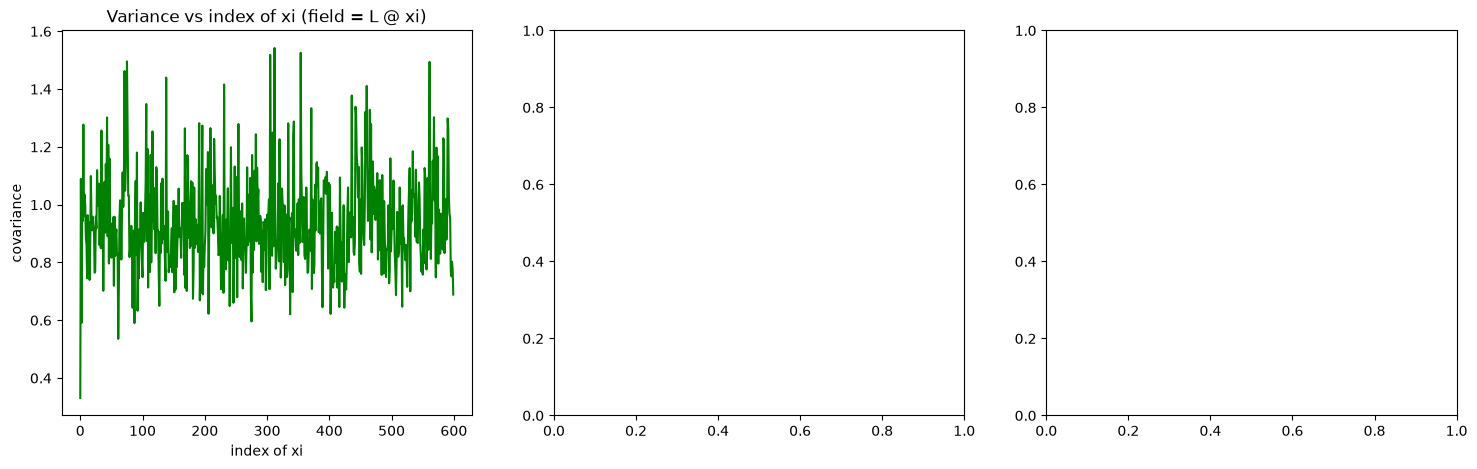

In [41]:
cov_diag = jnp.diag(cov)
important_cov_diag = cov_diag[3:3 + num_dimensions]
fig, axes = plt.subplots(1, 3, figsize = (18, 5))
axes[0].plot(jnp.arange(num_dimensions), important_cov_diag, color = "green")
axes[0].set_xlabel("index of xi")
axes[0].set_ylabel("covariance")
axes[0].set_title("Variance vs index of xi (field = L @ xi)")

Text(0, 0.5, 'log(extinction)')

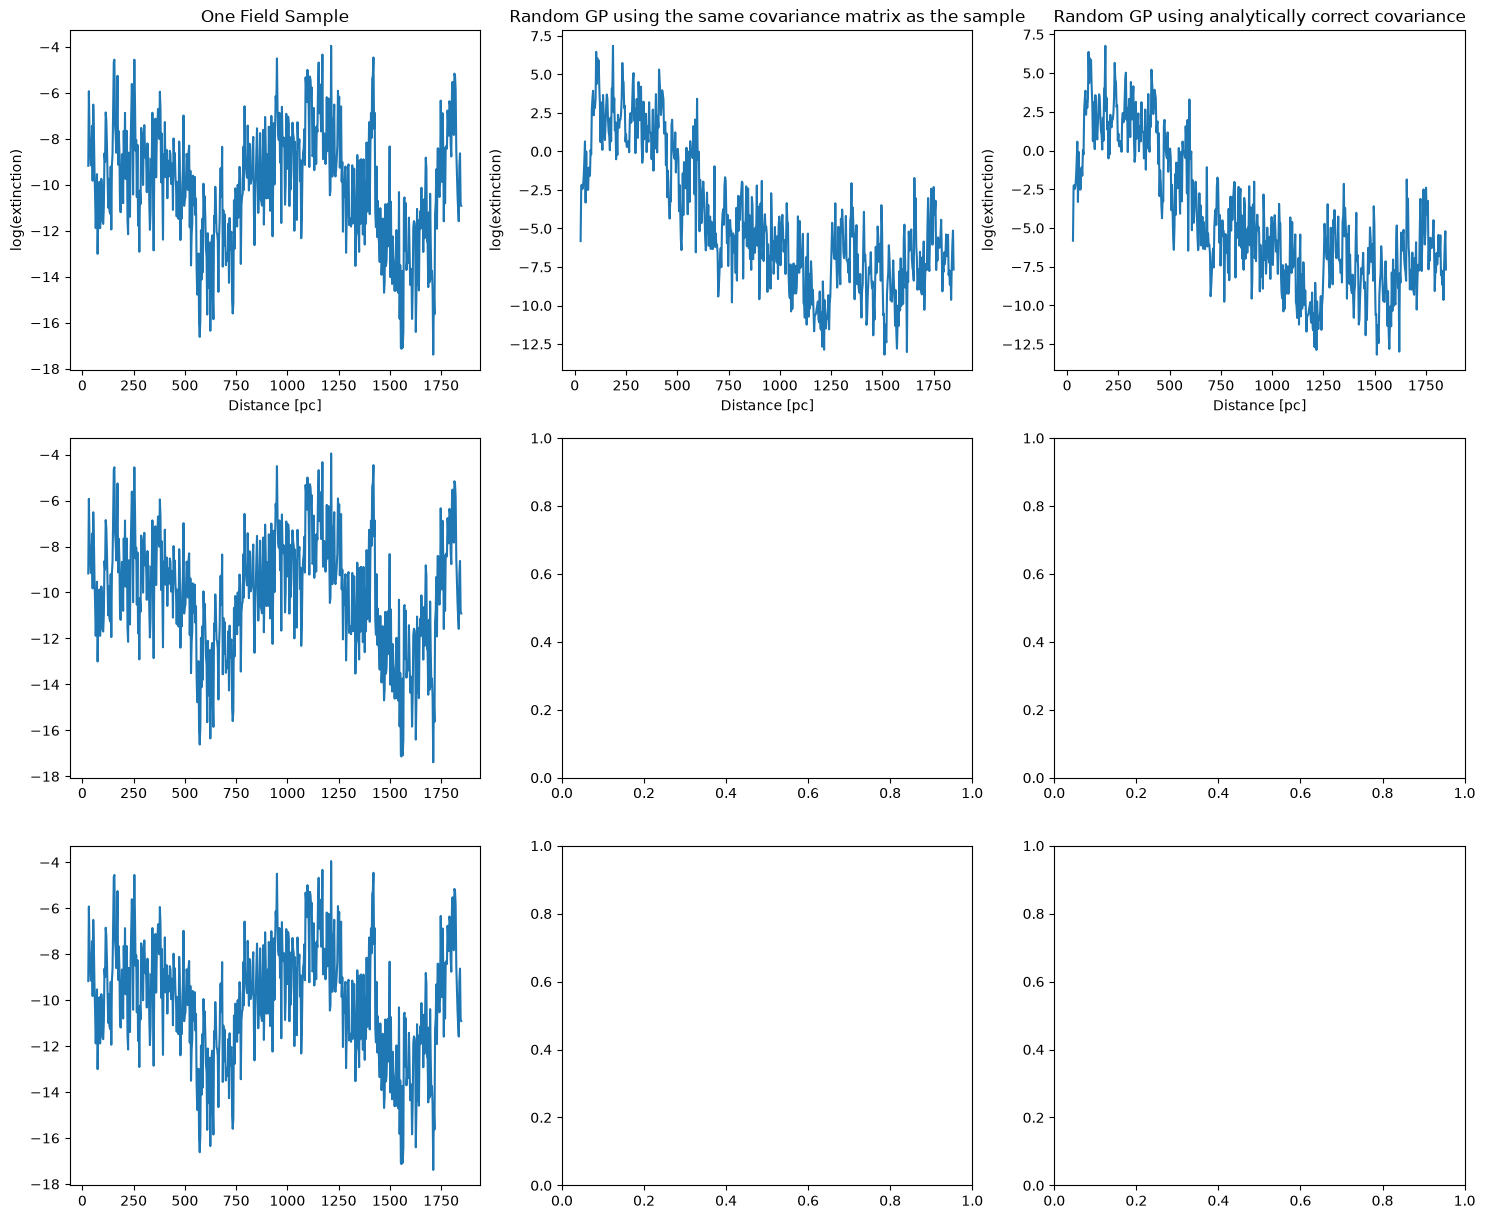

In [45]:
rng = jr.PRNGKey(0)
rng, k1, k2, k3 = jr.split(rng, 4)

fig, axes = plt.subplots(3, 3, figsize = (18, 15))
axes[0][0].plot(dust_x_linspace, overall_extinction_arr_raw[0, :])
axes[0][0].set_title("One Field Sample")
axes[1][0].plot(dust_x_linspace, overall_extinction_arr_raw[1, :])
axes[2][0].plot(dust_x_linspace, overall_extinction_arr_raw[2, :])
axes[0][0].set_xlabel("Distance [pc]")
axes[0][0].set_ylabel("log(extinction)")
true_cov_at_cov_bins_0 = matern_covariance(cov_bins, (logvars[0], lognus[0]))
true_cov_matrix = jnp.interp(DIST_MATRIX, cov_bins, true_cov_at_cov_bins_0)
L = jnp.linalg.cholesky(true_cov_matrix + 1e-6*jnp.exp(logvars[0])*jnp.eye(num_dimensions))
noise = jr.normal(k1, shape = (num_dimensions,))
field_true_cov = L @ noise
axes[0][2].plot(dust_x_linspace, field_true_cov)
axes[0][2].set_title("Random GP using analytically correct covariance")
field_same_cov = get_field_from_xi(noise, (logvars[0], lognus[0]), 0)
axes[0][1].plot(dust_x_linspace, field_same_cov)
axes[0][1].set_title("Random GP using the same covariance matrix as the sample")
axes[0][2].set_xlabel("Distance [pc]")
axes[0][1].set_xlabel("Distance [pc]")
axes[0][2].set_ylabel("log(extinction)")
axes[0][1].set_ylabel("log(extinction)")